In [4]:
import pandas as pd

df = pd.read_csv('vietnam_housing_dataset.csv')

print("Kích thước dữ liệu (số dòng, số cột):", df.shape)
df.head()

Kích thước dữ liệu (số dòng, số cột): (30229, 12)


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


Hệ số chặn (Intercept): 5.5820
Hệ số góc (Slope): 0.0043
Sai số MSE: 4.8132
Điểm R^2: 0.0129


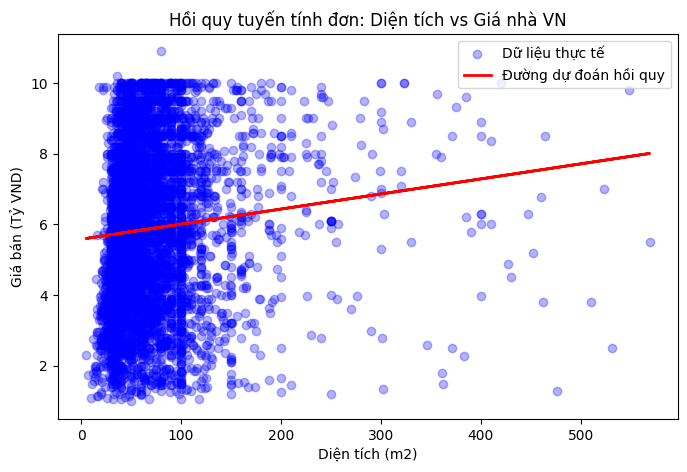

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('vietnam_housing_dataset.csv')
df_clean = df[['Area', 'Price']].dropna()

x = df_clean[['Area']]
y = df_clean['Price']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size= 0.2, random_state= 42)
model = LinearRegression()
model.fit(x_train, y_train)

y_doan =  model.predict(x_test)

print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Hệ số góc (Slope): {model.coef_[0]:.4f}")
print(f"Sai số MSE: {mean_squared_error(y_test, y_doan):.4f}")
print(f"Điểm R^2: {r2_score(y_test, y_doan):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(x_test, y_test, color="blue", alpha=0.3, label="Dữ liệu thực tế")
plt.plot(x_test, y_doan, color="red", linewidth=2, label="Đường dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn: Diện tích vs Giá nhà VN")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (Tỷ VND)")
plt.legend()
plt.show()

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('vietnam_housing_dataset.csv')
df_clean = df[['Area', 'Price']].dropna()

x = df_clean[['Area']]
np.random.seed(42)
nhieu = np.random.normal(0, 2, size=len(df_clean))
y_co_nhieu = df_clean['Price'] + nhieu

x_train, x_test, y_train, y_test = train_test_split(x, y_co_nhieu, test_size=0.2, random_state=42)
model_nhieu = LinearRegression()
model_nhieu.fit(x_train, y_train)
y_doan_nhieu = model_nhieu.predict(x_test)

print("--- KẾT QUẢ KHI THÊM NHIỄU ---")
print(f"Sai số MSE: {mean_squared_error(y_test, y_doan_nhieu):.4f}")
print(f"Điểm R^2: {r2_score(y_test, y_doan_nhieu):.4f}")

--- KẾT QUẢ KHI THÊM NHIỄU ---
Sai số MSE: 8.7636
Điểm R^2: 0.0051


In [10]:
cac_cot = ['Area', 'Frontage', 'Access Road', 'Floors', 'Bedrooms', 'Bathrooms']
df_da_bien = df[cac_cot + ['Price']].dropna()

X_multi = df_da_bien[cac_cot]
y_multi = df_da_bien['Price']

X_train, X_test, y_train, y_test = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)
y_doan_multi = model_multi.predict(X_test)

print("--- KẾT QUẢ HỒI QUY ĐA BIẾN ---")
print(f"Hệ số chặn (Intercept): {model_multi.intercept_:.4f}")
for ten_cot, he_so in zip(cac_cot, model_multi.coef_):
    print(f"Hệ số của {ten_cot}: {he_so:.4f}")

print(f"\nSai số MSE: {mean_squared_error(y_test, y_doan_multi):.4f}")
print(f"Điểm R^2: {r2_score(y_test, y_doan_multi):.4f}")

--- KẾT QUẢ HỒI QUY ĐA BIẾN ---
Hệ số chặn (Intercept): 2.0331
Hệ số của Area: 0.0080
Hệ số của Frontage: 0.0054
Hệ số của Access Road: 0.0299
Hệ số của Floors: 0.3958
Hệ số của Bedrooms: 0.1115
Hệ số của Bathrooms: 0.3646

Sai số MSE: 3.6393
Điểm R^2: 0.2507
